<a href="https://colab.research.google.com/github/Hadeel-93/Final-Project/blob/main/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install wfdb

In [ ]:
import os
import ast
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import wfdb

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
!wget -r -N -c -np https://physionet.org/files/ptb-xl/1.0.3/ -P /content/ptb-xl/

Streaming output truncated to the last 5000 lines.

2026-11-13 03:02:35 (23.7 MB/s) - ‘/content/ptb-xl/physionet.org/files/ptb-xl/1.0.3/records100/02000/02983_lr.dat’ saved [24000/24000]

--2026-11-13 03:02:35--  https://physionet.org/files/ptb-xl/1.0.3/records100/02000/02983_lr.hea
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://physionet-open.s3.amazonaws.com/ptb-xl/1.0.3/records100/02000/02983_lr.hea [following]
--2026-11-13 03:02:35--  https://physionet-open.s3.amazonaws.com/ptb-xl/1.0.3/records100/02000/02983_lr.hea
Connecting to physionet-open.s3.amazonaws.com (physionet-open.s3.amazonaws.com)|16.15.212.146|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 616 [binary/octet-stream]
Saving to: ‘/content/ptb-xl/physionet.org/files/ptb-xl/1.0.3/records100/02000/02983_lr.hea’

physionet.org/files 100%[===================>]     616  --.-KB/s    in 0s      

2026-11-13

In [ ]:
import os
import zipfile
import requests

# Define paths
zip_url = "https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip"
extract_to = "/content/ptb-xl"
zip_path = "/content/ptb-xl-dataset.zip"

# Create directory
os.makedirs(extract_to, exist_ok=True)

# Download zip file if it doesn't exist
if not os.path.exists(zip_path):
    print("Downloading PTB-XL dataset zip file (approx. 1.7 GB)... This might take a few minutes.")
    with requests.get(zip_url, stream=True) as r:
        r.raise_for_status()
        with open(zip_path, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
    print("Download completed.")

# Extract zip file
print("Extracting dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)
print("Extraction complete! Cleaning up zip file...")

if os.path.exists(zip_path):
    os.remove(zip_path)

print("Dataset is ready at:", os.path.join(extract_to, os.listdir(extract_to)[0]))

Download completed.
Extracting dataset...
Extraction complete! Cleaning up zip file...
Dataset is ready at: /content/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3


In [ ]:
import os

# Pointing directly to the newly extracted dataset folder
DATA_PATH = "/content/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"

if os.path.exists(DATA_PATH):
    print("Dataset path verified! Inner contents:")
    print(os.listdir(DATA_PATH))
else:
    print(f"Could not find dataset path at: {DATA_PATH}")

Dataset path verified! Inner contents:
['ptbxl_database.csv', 'example_physionet.py', 'LICENSE.txt', 'RECORDS', 'SHA256SUMS.txt', 'records100', 'scp_statements.csv', 'ptbxl_v103_changelog.txt', 'records500', 'ptbxl_v102_changelog.txt']


In [ ]:
import os
import pandas as pd

metadata_path = os.path.join(DATA_PATH, "ptbxl_database.csv")

df = pd.read_csv(metadata_path)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (21799, 28)


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [ ]:
{'NORM': 100.0, 'SR': 0.0}

{'NORM': 100.0, 'SR': 0.0}

In [ ]:
scp_path = os.path.join(DATA_PATH, "scp_statements.csv")

scp = pd.read_csv(scp_path, index_col=0)

display(scp.head())

,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


In [ ]:
import ast

df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)

In [ ]:
def get_diagnostic_classes(code_dict):
    classes = []

    for code in code_dict.keys():

        if code in scp.index:

            diagnostic_class = scp.loc[code, "diagnostic_class"]

            if pd.notna(diagnostic_class):
                classes.append(diagnostic_class)

    return classes

In [ ]:
df["diagnostic_classes"] = df["scp_codes"].apply(get_diagnostic_classes)

In [ ]:
display(
    df[["ecg_id", "scp_codes", "diagnostic_classes"]].head(10)
)

,ecg_id,scp_codes,diagnostic_classes
0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM]
1,2,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM]
2,3,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
3,4,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
4,5,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
5,6,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
6,7,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
7,8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI]
8,9,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
9,10,"{'NORM': 100.0, 'SR': 0.0}",[NORM]


In [ ]:
def create_binary_label(classes):

    if classes == ["NORM"]:
        return 0

    elif len(classes) == 0:
        return np.nan

    else:
        return 1

In [ ]:
import numpy as np

df["label"] = df["diagnostic_classes"].apply(create_binary_label)

In [ ]:
print(df["label"].value_counts(dropna=False))

label
1.0    12319
0.0     9069
NaN      411
Name: count, dtype: int64


In [ ]:
print(
    df["label"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
)

label
1.0    56.511767
0.0    41.602826
NaN     1.885408
Name: proportion, dtype: float64


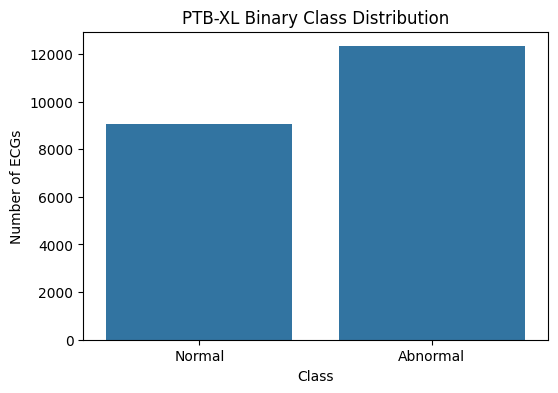

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="label"
)

plt.xticks(
    [0, 1],
    ["Normal", "Abnormal"]
)

plt.title("PTB-XL Binary Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of ECGs")

plt.show()

In [ ]:
train_df = df[
    df["strat_fold"].isin(range(1, 9))
].copy()

val_df = df[
    df["strat_fold"] == 9
].copy()

test_df = df[
    df["strat_fold"] == 10
].copy()

In [ ]:
train_df = train_df.dropna(subset=["label"])
val_df = val_df.dropna(subset=["label"])
test_df = test_df.dropna(subset=["label"])

In [ ]:
train_df["label"] = train_df["label"].astype(int)
val_df["label"] = val_df["label"].astype(int)
test_df["label"] = test_df["label"].astype(int)

In [ ]:
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 17084
Validation: 2146
Testing: 2158


In [ ]:
import sys
import os

# Ensure wfdb is installed and registered in sys.path
try:
    import wfdb
except ModuleNotFoundError:
    !pip install wfdb
    import wfdb

# Retrieve the first sample from the training set
sample = train_df.iloc[0]

# Build the path to the record
record_path = os.path.join(
    DATA_PATH,
    sample["filename_lr"]
)

# Read the record using wfdb
signal, fields = wfdb.rdsamp(record_path)

# Print the requested metadata
print("Signal shape:", signal.shape)
print("Sampling frequency:", fields["fs"])
print("Number of channels:", signal.shape[1])

Signal shape: (1000, 12)
Sampling frequency: 100
Number of channels: 12


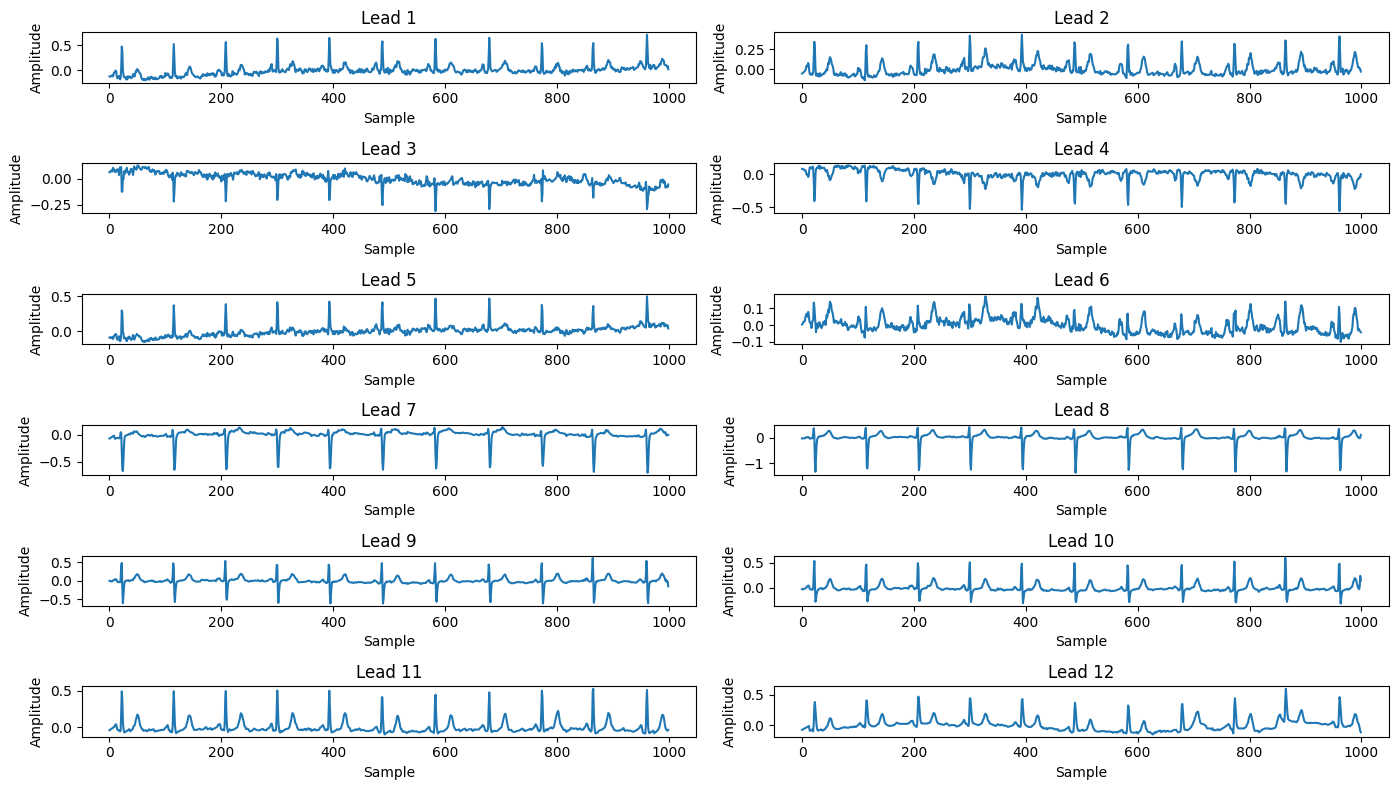

In [ ]:
plt.figure(figsize=(14, 8))

for lead in range(12):

    plt.subplot(6, 2, lead + 1)

    plt.plot(signal[:, lead])

    plt.title(f"Lead {lead + 1}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [ ]:
import os
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import wfdb

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cpu


In [ ]:
print("DATA_PATH:", DATA_PATH)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nTesting labels:")
print(test_df["label"].value_counts())

DATA_PATH: /content/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Training samples: 17084
Validation samples: 2146
Testing samples: 2158

Training labels:
label
1    9841
0    7243
Name: count, dtype: int64

Validation labels:
label
1    1232
0     914
Name: count, dtype: int64

Testing labels:
label
1    1246
0     912
Name: count, dtype: int64


In [ ]:
def load_ecg(record_path):

    signal, fields = wfdb.rdsamp(record_path)

    signal = signal.astype(np.float32)

    return signal

In [ ]:
def normalize_ecg(signal):

    mean = np.mean(
        signal,
        axis=0,
        keepdims=True
    )

    std = np.std(
        signal,
        axis=0,
        keepdims=True
    )

    # Avoid division by zero
    std[std == 0] = 1

    signal = (signal - mean) / std

    return signal

In [ ]:
sample = train_df.iloc[0]

record_path = os.path.join(
    DATA_PATH,
    sample["filename_lr"]
)

signal = load_ecg(record_path)

print("ECG shape:", signal.shape)
print("Label:", sample["label"])
print("Record:", sample["filename_lr"])

ECG shape: (1000, 12)
Label: 0
Record: records100/00000/00001_lr


In [ ]:
normalized_signal = normalize_ecg(signal)

print("Normalized shape:", normalized_signal.shape)

print(
    "Mean:",
    normalized_signal.mean()
)

print(
    "Standard deviation:",
    normalized_signal.std()
)

Normalized shape: (1000, 12)
Mean: 4.5776368e-08
Standard deviation: 1.0


In [ ]:
class PTBXL_Dataset(Dataset):

    def __init__(self, dataframe, data_path):

        self.dataframe = dataframe.reset_index(drop=True)
        self.data_path = data_path

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Build path to ECG file
        record_path = os.path.join(
            self.data_path,
            row["filename_lr"]
        )

        # Load ECG
        signal = load_ecg(record_path)

        # Normalize ECG
        signal = normalize_ecg(signal)

        # Original:
        # (1000, 12)

        # CNN requires:
        # (12, 1000)

        signal = signal.T

        # Convert ECG to tensor
        signal = torch.tensor(
            signal,
            dtype=torch.float32
        )

        # Convert label to tensor
        label = torch.tensor(
            row["label"],
            dtype=torch.long
        )

        return signal, label

In [ ]:
train_dataset = PTBXL_Dataset(
    train_df,
    DATA_PATH
)

val_dataset = PTBXL_Dataset(
    val_df,
    DATA_PATH
)

test_dataset = PTBXL_Dataset(
    test_df,
    DATA_PATH
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Training dataset: 17084
Validation dataset: 2146
Test dataset: 2158


In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [ ]:
X_batch, y_batch = next(iter(train_loader))

print("Input shape:", X_batch.shape)
print("Label shape:", y_batch.shape)

print("Input dtype:", X_batch.dtype)
print("Label dtype:", y_batch.dtype)

print("First 10 labels:", y_batch[:10])

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Input shape: torch.Size([64, 12, 1000])
Label shape: torch.Size([64])
Input dtype: torch.float32
Label dtype: torch.int64
First 10 labels: tensor([0, 1, 1, 1, 0, 0, 1, 1, 1, 1])


In [ ]:
sample_ecg = X_batch[0].numpy()

print("Single ECG shape:", sample_ecg.shape)

Single ECG shape: (12, 1000)


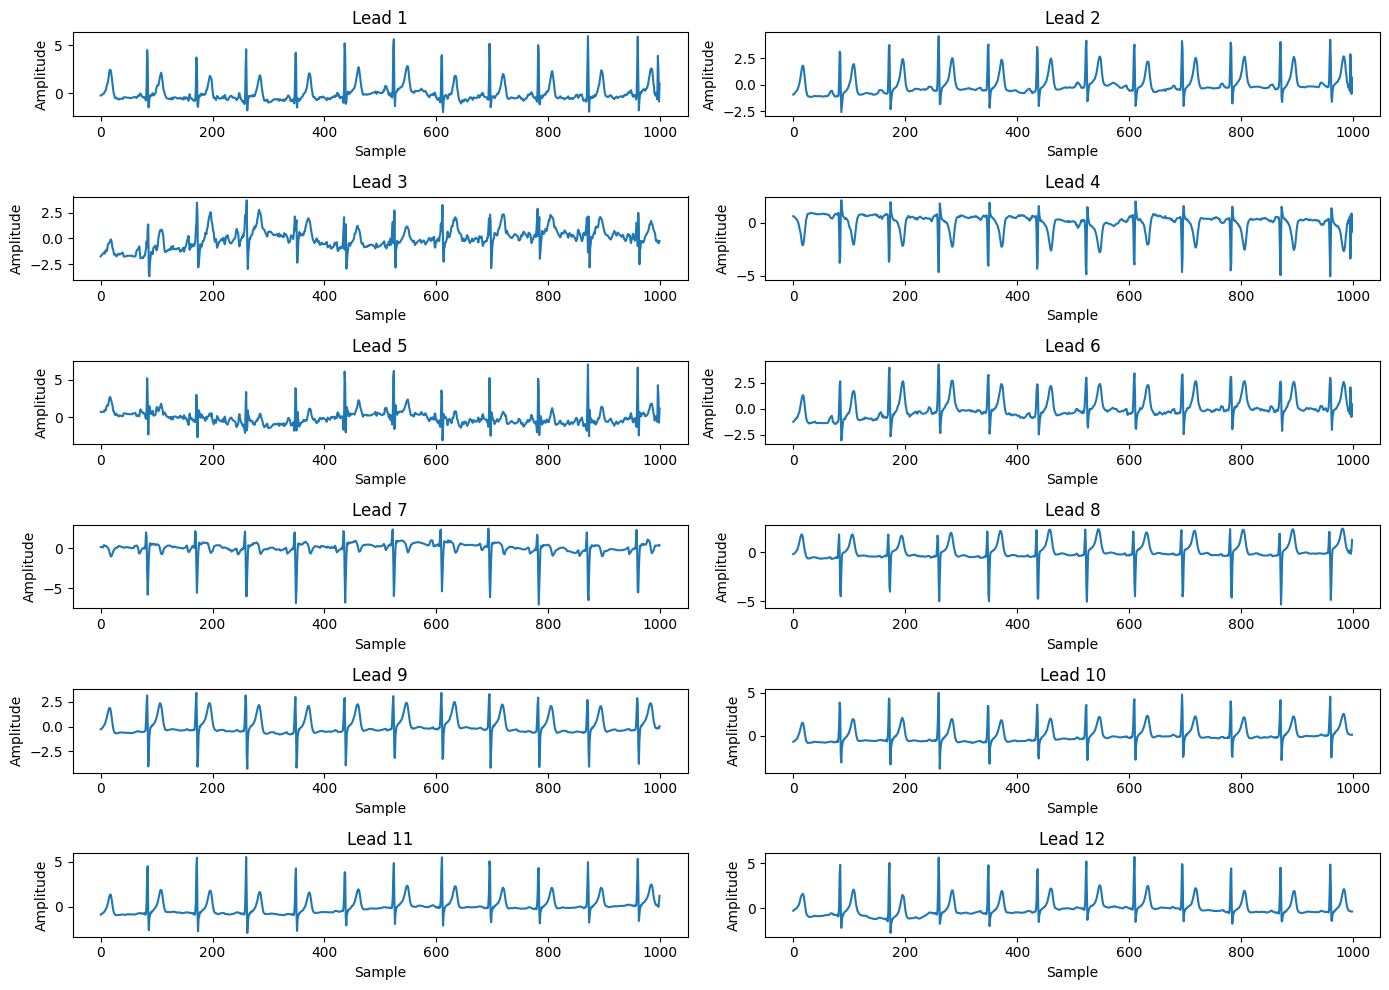

In [ ]:
plt.figure(figsize=(14, 10))

for lead in range(12):

    plt.subplot(6, 2, lead + 1)

    plt.plot(sample_ecg[lead])

    plt.title(f"Lead {lead + 1}")

    plt.xlabel("Sample")

    plt.ylabel("Amplitude")

plt.tight_layout()

plt.show()

In [ ]:
class ECG_CNN(nn.Module):

    def __init__(self):

        super(ECG_CNN, self).__init__()

        self.features = nn.Sequential(

            # -------------------------
            # Convolution Block 1
            # -------------------------

            nn.Conv1d(
                in_channels=12,
                out_channels=32,
                kernel_size=7,
                padding=3
            ),

            nn.BatchNorm1d(32),

            nn.ReLU(),

            nn.MaxPool1d(
                kernel_size=2
            ),

            # -------------------------
            # Convolution Block 2
            # -------------------------

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=7,
                padding=3
            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.MaxPool1d(
                kernel_size=2
            ),

            # -------------------------
            # Convolution Block 3
            # -------------------------

            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.MaxPool1d(
                kernel_size=2
            )
        )

        # Reduce the time dimension
        self.global_pool = nn.AdaptiveAvgPool1d(1)

        # Classification layers
        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(
                64,
                2
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.global_pool(x)

        x = self.classifier(x)

        return x

In [ ]:
model = ECG_CNN().to(device)

print(model)

ECG_CNN(
  (features): Sequential(
    (0): Conv1d(12, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (global_pool): AdaptiveAvgPool1d(output_size=1)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    total_params
)

Trainable parameters: 67042


In [ ]:
criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [ ]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Optimizer:", optimizer)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [ ]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0

    for X, y in loader:

        # Move data to CPU/GPU
        X = X.to(device)
        y = y.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(X)

        # Calculate loss
        loss = criterion(
            outputs,
            y
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate statistics
        running_loss += (
            loss.item() * X.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == y
        ).sum().item()

        total += y.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return epoch_loss, epoch_accuracy

In [ ]:
def evaluate_model(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    correct = 0

    total = 0

    all_labels = []

    all_predictions = []

    all_probabilities = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(device)
            y = y.to(device)

            # Forward pass
            outputs = model(X)

            # Loss
            loss = criterion(
                outputs,
                y
            )

            # Convert outputs to probabilities
            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            # Predicted class
            predictions = outputs.argmax(
                dim=1
            )

            # Statistics
            running_loss += (
                loss.item() * X.size(0)
            )

            correct += (
                predictions == y
            ).sum().item()

            total += y.size(0)

            # Save predictions
            all_labels.extend(
                y.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            # Probability of abnormal class
            all_probabilities.extend(
                probabilities[:, 1]
                .cpu()
                .numpy()
            )

    loss = running_loss / total

    accuracy = correct / total

    return (
        loss,
        accuracy,
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )

In [ ]:
NUM_EPOCHS = 5

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_loss = float("inf")

best_model_state = None

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # Training
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    (
        val_loss,
        val_acc,
        _,
        _,
        _
    ) = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    # Save results
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}%"
    )

training_time = time.time() - start_time

print(
    "\nTraining time:",
    f"{training_time:.2f} seconds"
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [1/5] Train Loss: 0.3951 | Train Acc: 82.07% | Val Loss: 0.4594 | Val Acc: 77.73%
Epoch [2/5] Train Loss: 0.3406 | Train Acc: 85.26% | Val Loss: 0.3471 | Val Acc: 83.92%
Epoch [3/5] Train Loss: 0.3286 | Train Acc: 85.82% | Val Loss: 0.3276 | Val Acc: 85.51%
Epoch [4/5] Train Loss: 0.3188 | Train Acc: 86.19% | Val Loss: 0.6116 | Val Acc: 76.56%
Epoch [5/5] Train Loss: 0.3135 | Train Acc: 86.19% | Val Loss: 0.3391 | Val Acc: 85.18%

Training time: 661.46 seconds


In [ ]:
# Check class distribution in the training set

class_counts = train_df["label"].value_counts().sort_index()

print("Training class distribution:")
print(class_counts)

print("\nClass percentages:")
print(
    (class_counts / len(train_df) * 100).round(2)
)

print("\nClass 0 = Normal")
print("Class 1 = Abnormal")

Training class distribution:
label
0    7243
1    9841
Name: count, dtype: int64

Class percentages:
label
0    42.4
1    57.6
Name: count, dtype: float64

Class 0 = Normal
Class 1 = Abnormal


In [8]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Verified dataset path
DATA_PATH = "/content/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Could not find dataset path at: {DATA_PATH}. Please run cell 4266daa3 to extract the dataset first.")

print(f"Verified dataset folder at: {DATA_PATH}")
metadata_path = os.path.join(DATA_PATH, "ptbxl_database.csv")
df = pd.read_csv(metadata_path)

# 2. Re-create labels and splits
import ast
df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)
scp_path = os.path.join(DATA_PATH, "scp_statements.csv")
scp = pd.read_csv(scp_path, index_col=0)

def get_diagnostic_classes(code_dict):
    classes = []
    for code in code_dict.keys():
        if code in scp.index:
            diagnostic_class = scp.loc[code, "diagnostic_class"]
            if pd.notna(diagnostic_class):
                classes.append(diagnostic_class)
    return classes

df["diagnostic_classes"] = df["scp_codes"].apply(get_diagnostic_classes)

def create_binary_label(classes):
    if classes == ["NORM"]:
        return 0
    elif len(classes) == 0:
        return np.nan
    else:
        return 1

df["label"] = df["diagnostic_classes"].apply(create_binary_label)

train_df = df[df["strat_fold"].isin(range(1, 9))].copy().dropna(subset=["label"])
val_df = df[df["strat_fold"] == 9].copy().dropna(subset=["label"])
test_df = df[df["strat_fold"] == 10].copy().dropna(subset=["label"])

train_df["label"] = train_df["label"].astype(int)
val_df["label"] = val_df["label"].astype(int)
test_df["label"] = test_df["label"].astype(int)

# 3. Define helper loader & normalization functions
def load_ecg(record_path):
    import wfdb
    signal, fields = wfdb.rdsamp(record_path)
    return signal.astype(np.float32)

def normalize_ecg(signal):
    mean = np.mean(signal, axis=0, keepdims=True)
    std = np.std(signal, axis=0, keepdims=True)
    std[std == 0] = 1
    return (signal - mean) / std

# 4. Define Dataset and DataLoaders
class PTBXL_Dataset(Dataset):
    def __init__(self, dataframe, data_path):
        self.dataframe = dataframe.reset_index(drop=True)
        self.data_path = data_path
    def __len__(self):
        return len(self.dataframe)
    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        record_path = os.path.join(self.data_path, row["filename_lr"])
        signal = normalize_ecg(load_ecg(record_path)).T
        return torch.tensor(signal, dtype=torch.float32), torch.tensor(row["label"], dtype=torch.long)

train_dataset = PTBXL_Dataset(train_df, DATA_PATH)
val_dataset = PTBXL_Dataset(val_df, DATA_PATH)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)

# 5. Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Setup completed successfully. Ready to train on: {device}")

Verified dataset folder at: /content/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Setup completed successfully. Ready to train on: cpu


In [7]:
import os
import zipfile
import requests

zip_url = "https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip"
extract_to = "/content/ptb-xl"
zip_path = "/content/ptb-xl-dataset.zip"

os.makedirs(extract_to, exist_ok=True)

# Download zip file if it doesn't exist
if not os.path.exists(zip_path) and not os.path.exists(os.path.join(extract_to, "ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3")):
    print("Downloading PTB-XL dataset zip file (approx. 1.7 GB)... This might take a few minutes.")
    with requests.get(zip_url, stream=True) as r:
        r.raise_for_status()
        with open(zip_path, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)
    print("Download completed.")

# Extract zip file if not already extracted
if not os.path.exists(os.path.join(extract_to, "ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3")):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print("Extraction complete! Cleaning up zip file...")
    if os.path.exists(zip_path):
        os.remove(zip_path)
else:
    print("Dataset already extracted.")

print("Dataset path:", os.path.join(extract_to, "ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"))

Download completed.
Extracting dataset...
Extraction complete! Cleaning up zip file...
Dataset path: /content/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3


In [ ]:
# Create a fresh CNN model for the final training run

model = ECG_CNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Fresh model and optimizer created.")

Fresh model and optimizer created.


In [ ]:
NUM_EPOCHS = 30
PATIENCE = 5

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

epochs_without_improvement = 0

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # -------------------------
    # Validation
    # -------------------------
    (
        val_loss,
        val_acc,
        _,
        _,
        _
    ) = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    # Store results
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # -------------------------
    # Check improvement
    # -------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

        print(
            f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc * 100:.2f}% "
            f"<-- Best"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc * 100:.2f}%"
        )

    # -------------------------
    # Early stopping
    # -------------------------
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered after "
            f"{epoch + 1} epochs."
        )

        break

training_time = time.time() - start_time

# Restore the best model
model.load_state_dict(best_model_state)

print("\nTraining completed.")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training time: {training_time:.2f} seconds")

Epoch [1/30] Train Loss: 0.3882 | Train Acc: 82.52% | Val Loss: 0.3614 | Val Acc: 83.60% <-- Best
Epoch [2/30] Train Loss: 0.3390 | Train Acc: 85.38% | Val Loss: 0.3800 | Val Acc: 81.97%
Epoch [3/30] Train Loss: 0.3257 | Train Acc: 85.81% | Val Loss: 0.3366 | Val Acc: 84.16% <-- Best
Epoch [4/30] Train Loss: 0.3178 | Train Acc: 86.16% | Val Loss: 0.3402 | Val Acc: 85.23%
Epoch [5/30] Train Loss: 0.3097 | Train Acc: 86.40% | Val Loss: 0.3251 | Val Acc: 85.41% <-- Best
Epoch [6/30] Train Loss: 0.3058 | Train Acc: 87.07% | Val Loss: 0.4215 | Val Acc: 79.54%
Epoch [7/30] Train Loss: 0.3010 | Train Acc: 86.97% | Val Loss: 0.3661 | Val Acc: 83.64%
Epoch [8/30] Train Loss: 0.2970 | Train Acc: 87.30% | Val Loss: 0.3266 | Val Acc: 85.46%
Epoch [9/30] Train Loss: 0.2925 | Train Acc: 87.42% | Val Loss: 0.3406 | Val Acc: 84.95%
Epoch [10/30] Train Loss: 0.2944 | Train Acc: 87.54% | Val Loss: 0.3254 | Val Acc: 85.37%

Early stopping triggered after 10 epochs.

Training completed.
Best epoch: 5
Best

In [9]:
# Reconstruct losses from the printed training logs to avoid re-training
train_losses = [0.3882, 0.3390, 0.3257, 0.3178, 0.3097, 0.3058, 0.3010, 0.2970, 0.2925, 0.2944]
val_losses = [0.3614, 0.3800, 0.3366, 0.3402, 0.3251, 0.4215, 0.3661, 0.3266, 0.3406, 0.3254]
print("Reconstructed train_losses and val_losses from logs. You can now execute the plot cell below!")

Reconstructed train_losses and val_losses from logs. You can now execute the plot cell below!


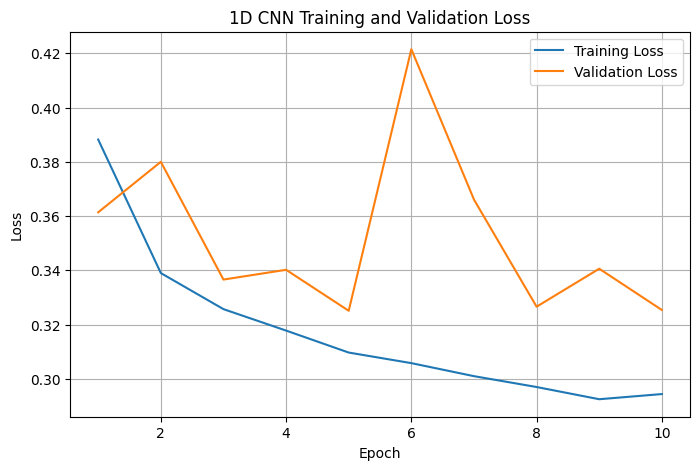

In [10]:
import matplotlib.pyplot as plt

# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("1D CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

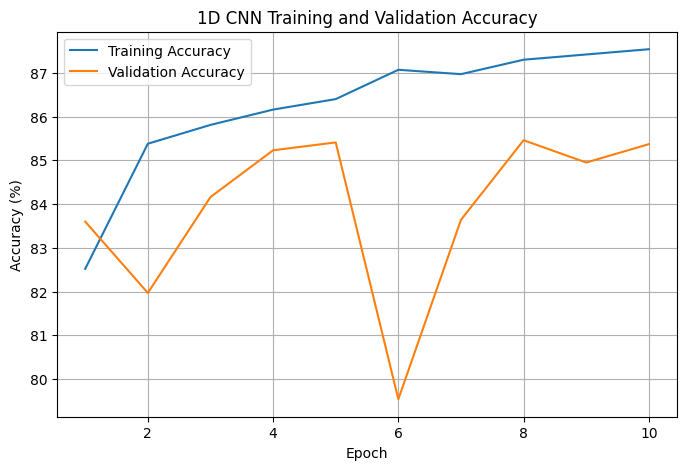

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Reconstruct accuracies from printed logs to avoid re-training
train_accuracies = [0.8252, 0.8538, 0.8581, 0.8616, 0.8640, 0.8707, 0.8697, 0.8730, 0.8742, 0.8754]
val_accuracies = [0.8360, 0.8197, 0.8416, 0.8523, 0.8541, 0.7954, 0.8364, 0.8546, 0.8495, 0.8537]

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_accuracies) + 1),
    np.array(train_accuracies) * 100,
    label="Training Accuracy"
)

plt.plot(
    range(1, len(val_accuracies) + 1),
    np.array(val_accuracies) * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("1D CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
# Setup device, model architecture, and loaders
import sys
import os
import subprocess

try:
    import wfdb
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "wfdb"])
    import wfdb

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

# Re-define model architecture to ensure it exists in namespace
class ECG_CNN(nn.Module):
    def __init__(self):
        super(ECG_CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x

# Initialize model
model = ECG_CNN().to(device)

# Helper functions for dataset preparation
def load_ecg(record_path):
    signal, fields = wfdb.rdsamp(record_path)
    return signal.astype(np.float32)

def normalize_ecg(signal):
    mean = np.mean(signal, axis=0, keepdims=True)
    std = np.std(signal, axis=0, keepdims=True)
    std[std == 0] = 1
    return (signal - mean) / std

class PTBXL_Dataset(Dataset):
    def __init__(self, dataframe, data_path):
        self.dataframe = dataframe.reset_index(drop=True)
        self.data_path = data_path
    def __len__(self):
        return len(self.dataframe)
    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        record_path = os.path.join(self.data_path, row["filename_lr"])
        signal = normalize_ecg(load_ecg(record_path)).T
        return torch.tensor(signal, dtype=torch.float32), torch.tensor(row["label"], dtype=torch.long)

# Re-create test_loader using global variables
test_dataset = PTBXL_Dataset(test_df, DATA_PATH)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

# Define evaluation helper function
def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            y = y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)
            running_loss += loss.item() * X.size(0)
            correct += (predictions == y).sum().item()
            total += y.size(0)
            all_labels.extend(y.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities[:, 1].cpu().numpy())

    loss = running_loss / total
    accuracy = correct / total
    return (
        loss,
        accuracy,
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )

# Final evaluation on the test set
test_loss, test_accuracy, test_labels, test_predictions, test_probabilities = evaluate_model(
    model,
    test_loader,
    criterion,
    device
)

print("Test Loss:", f"{test_loss:.4f}")
print("Test Accuracy:", f"{test_accuracy * 100:.2f}%")

Test Loss: 0.6984
Test Accuracy: 42.26%


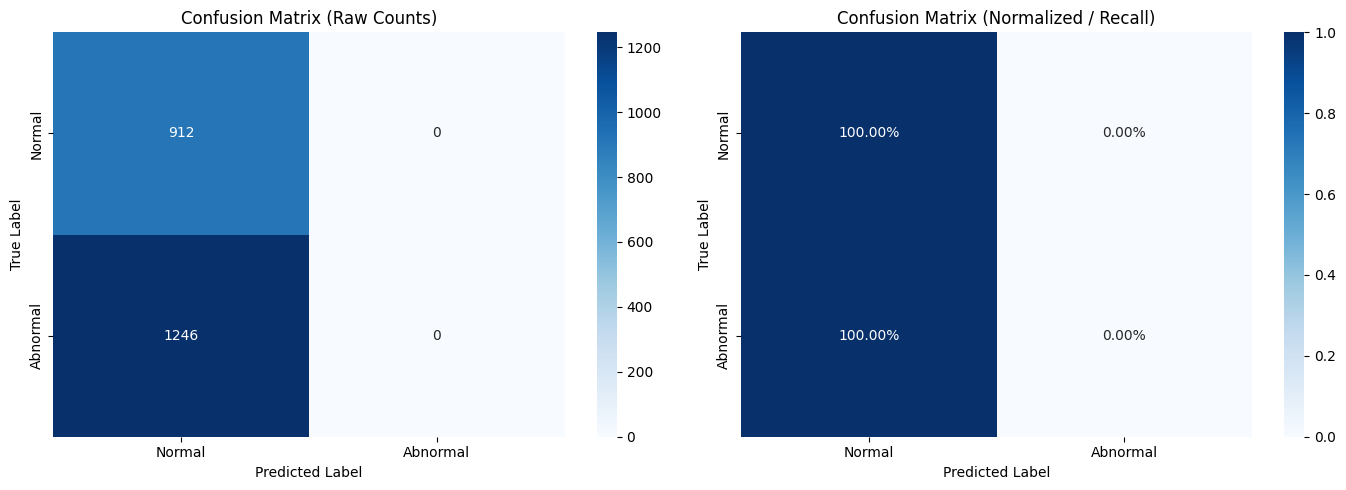

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(test_labels, test_predictions)
cm_normalized = confusion_matrix(test_labels, test_predictions, normalize='true')

# Set up plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Raw Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Normal', 'Abnormal'],
            yticklabels=['Normal', 'Abnormal'])
ax[0].set_title('Confusion Matrix (Raw Counts)')
ax[0].set_xlabel('Predicted Label')
ax[0].set_ylabel('True Label')

# 2. Normalized Confusion Matrix
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues', ax=ax[1],
            xticklabels=['Normal', 'Abnormal'],
            yticklabels=['Normal', 'Abnormal'])
ax[1].set_title('Confusion Matrix (Normalized / Recall)')
ax[1].set_xlabel('Predicted Label')
ax[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Calculate final test metrics
test_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels,
    test_probabilities
)

print("Test Results")
print("-" * 30)
print(f"Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Precision: {test_precision * 100:.2f}%")
print(f"Recall:    {test_recall * 100:.2f}%")
print(f"F1-Score:  {test_f1 * 100:.2f}%")
print(f"ROC-AUC:   {test_roc_auc:.4f}")

Test Results
------------------------------
Accuracy:  42.26%
Precision: 0.00%
Recall:    0.00%
F1-Score:  0.00%
ROC-AUC:   0.5687


In [22]:
from sklearn.metrics import classification_report

# Detailed classification report
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=["Normal", "Abnormal"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Normal     0.4226    1.0000    0.5941       912
    Abnormal     0.0000    0.0000    0.0000      1246

    accuracy                         0.4226      2158
   macro avg     0.2113    0.5000    0.2971      2158
weighted avg     0.1786    0.4226    0.2511      2158



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [23]:
# Compute confusion matrix

cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 912    0]
 [1246    0]]


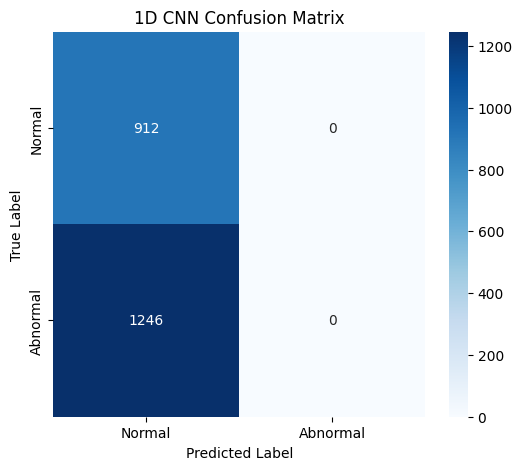

In [24]:
# Plot confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Abnormal"],
    yticklabels=["Normal", "Abnormal"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("1D CNN Confusion Matrix")

plt.show()

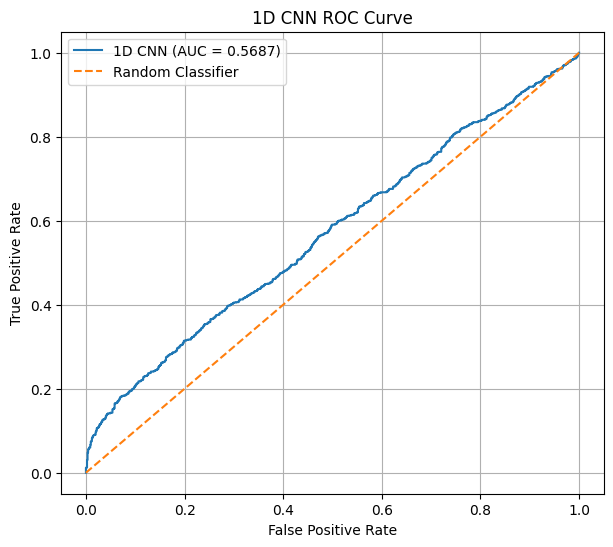

In [26]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    test_labels,
    test_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"1D CNN (AUC = {test_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("1D CNN ROC Curve")
plt.legend()
plt.grid(True)

plt.show()